# Section 4: Clustering Digits and Segmenting Customers

**What you'll learn**
- Group MNIST digits with k-means and judge the groups against held-back labels
- Choose k with inertia and silhouette
- Build a hierarchy with Ward linkage and read a dendrogram
- See DBSCAN and HDBSCAN call most points noise, and fix it with UMAP
- Get soft cluster memberships from a Gaussian mixture
- Segment 440 wholesale customers and describe each segment for a business team

## Setup
- Slides 1-2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

## Part 1: Clustering MNIST
- The first 10,000 digits keep every step fast
- The labels `y` are only used to grade the clusters

In [2]:
X, y = fetch_openml("mnist_784", return_X_y=True, as_frame=False)
X = X[:10000] / 255
y = y[:10000].astype(int)
X.shape

(10000, 784)

- Cluster on 50 PCA components instead of 784 pixels

In [3]:
pca = PCA(n_components=50)
X_pca = pca.fit_transform(X)
X_pca.shape

(10000, 50)

## k-Means
- Slides 3-5

In [4]:
km = KMeans(n_clusters=10)
labels = km.fit_predict(X_pca)
np.bincount(labels)

array([1227,  719, 1833, 1030, 1190,  550,  939, 1133,  933,  446])

- Rows are clusters, columns are the true digits

In [5]:
pd.crosstab(labels, y)

col_0,0,1,2,3,4,5,6,7,8,9
row_0,,,,,,,,,,
0,2,10,5,32,240,63,0,455,28,392
1,2,2,663,31,2,1,7,4,7,0
2,2,1106,168,65,42,187,82,61,102,18
3,27,3,23,214,0,231,7,1,523,1
4,31,3,61,637,0,237,5,2,198,16
5,480,0,11,18,0,23,9,2,3,4
6,8,1,23,12,395,29,98,98,31,244
7,2,1,7,12,282,54,0,447,31,297
8,31,1,29,10,19,28,795,0,17,3


- Purity: give each cluster its most common digit and count how many points agree

In [6]:
pd.crosstab(labels, y).max(axis=1).sum() / len(y)

np.float64(0.5917)

- Baseline: put every point in one cluster

In [7]:
pd.Series(y).value_counts(normalize=True).max()

np.float64(0.1127)

- Adjusted Rand index: 0 for random clusters, 1 for a perfect match

In [8]:
adjusted_rand_score(y, labels)

0.37153272656590447

- Each cluster centre, mapped back from 50 components to 784 pixels

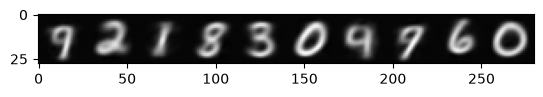

In [9]:
centres = pca.inverse_transform(km.cluster_centers_)
plt.imshow(np.hstack(centres.reshape(-1, 28, 28)), cmap="gray")

## Choosing k
- Slides 6-7

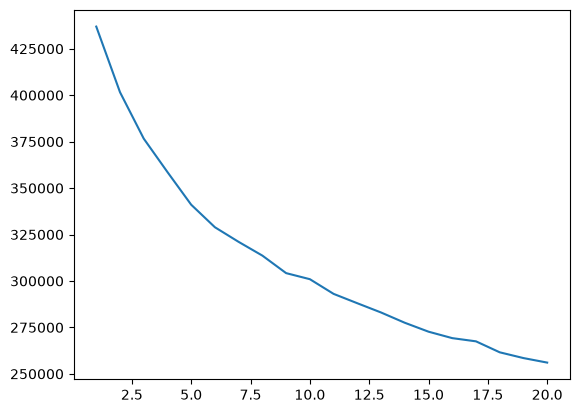

In [10]:
inertias = []
for k in range(1, 21):
    inertias.append(KMeans(n_clusters=k).fit(X_pca).inertia_)
plt.plot(range(1, 21), inertias)

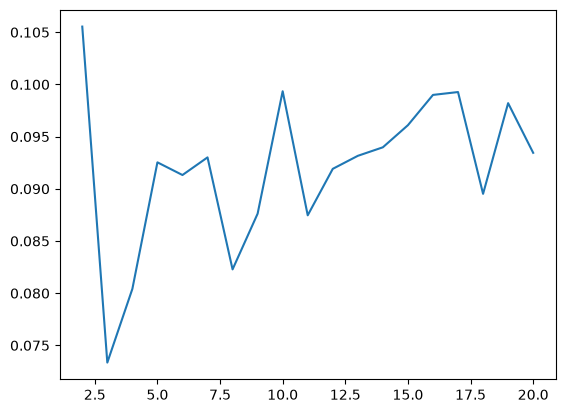

In [11]:
silhouettes = []
for k in range(2, 21):
    silhouettes.append(silhouette_score(X_pca, KMeans(n_clusters=k).fit_predict(X_pca)))
plt.plot(range(2, 21), silhouettes)

- 20 clusters: purity goes up, the Rand index does not

In [12]:
labels20 = KMeans(n_clusters=20).fit_predict(X_pca)
pd.crosstab(labels20, y).max(axis=1).sum() / len(y), adjusted_rand_score(y, labels20)

(np.float64(0.7015), 0.35405488387966566)

## Hierarchical Clustering
- Slides 8-9
- Ward linkage on 2,000 digits; the full 10,000 makes an unreadable tree

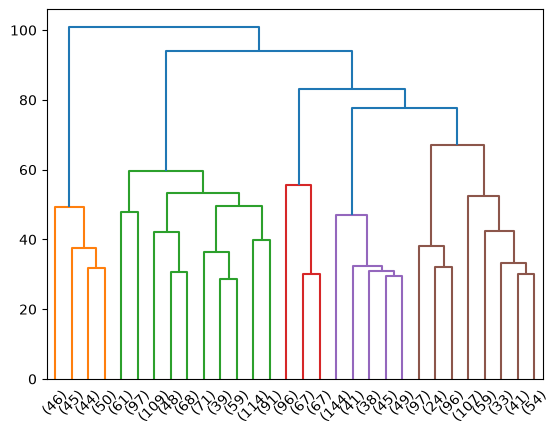

In [13]:
Z = linkage(X_pca[:2000], method="ward")
dendrogram(Z, truncate_mode="lastp", p=30)
plt.show()

- `AgglomerativeClustering` cuts the same kind of tree at 10 clusters

In [14]:
agg = AgglomerativeClustering(n_clusters=10)
labels = agg.fit_predict(X_pca)
adjusted_rand_score(y, labels)

0.5311015253085205

## DBSCAN
- Slides 10-11
- Label `-1` means noise: points in no cluster

In [15]:
db = DBSCAN(eps=4).fit_predict(X_pca)
(db == -1).mean(), db.max() + 1

(np.float64(0.3482), np.int64(38))

- Try `eps=3` and `eps=5`

## HDBSCAN
- Slides 12-13
- No `eps` to set: it tries every density level
- `copy=True` stops it from changing the input array

In [16]:
hdb = HDBSCAN(copy=True).fit_predict(X_pca)
(hdb == -1).mean(), hdb.max() + 1

(np.float64(0.7516), np.int64(51))

- UMAP to 10 dimensions first, then HDBSCAN

In [17]:
X_umap = umap.UMAP(n_components=10).fit_transform(X)
X_umap.shape

(10000, 10)

In [18]:
hdb = HDBSCAN(copy=True).fit_predict(X_umap)
(hdb == -1).mean(), hdb.max() + 1

(np.float64(0.0), np.int64(6))

In [19]:
pd.crosstab(hdb, y)

col_0,0,1,2,3,4,5,6,7,8,9
row_0,,,,,,,,,,
0,991,0,12,2,0,3,9,0,7,4
1,2,0,2,2,8,10,984,0,10,2
2,1,2,8,987,0,822,8,0,869,17
3,6,6,23,22,949,22,9,1050,35,951
4,0,4,919,6,0,1,0,3,3,1
5,1,1115,27,13,23,5,4,17,20,3


In [20]:
adjusted_rand_score(y, hdb)

0.533236918950586

## Gaussian Mixtures
- Slide 14

In [21]:
gmm = GaussianMixture(n_components=10)
gmm.fit(X_pca)
labels = gmm.predict(X_pca)
adjusted_rand_score(y, labels)

0.49159646754946335

- One probability per cluster for each digit

In [22]:
probs = gmm.predict_proba(X_pca)
probs[0].round(2)

array([1., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

- Share of digits with no cluster above 90%

In [23]:
(probs.max(axis=1) < 0.9).mean()

np.float64(0.01)

## Part 2: Segmenting Wholesale Customers
- Slide 15
- 440 customers of a Portuguese food wholesaler, yearly spend per product group
- `Channel` 1 is hotels, restaurants and cafés; 2 is retail: held back to grade

In [24]:
url = "https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip"
df = pd.read_csv(url)
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [25]:
df["Channel"].value_counts()

Channel
1    298
2    142
Name: count, dtype: int64

In [26]:
spend = df.drop(columns=["Channel", "Region"])
spend.describe()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


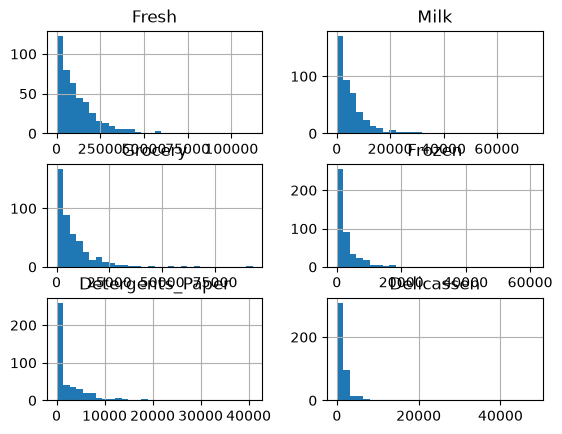

In [27]:
spend.hist(bins=30)
plt.show()

## Why Scaling Changes Clusters
- Slide 16
- Scaled raw spend: the biggest spenders dominate

In [28]:
X_raw = StandardScaler().fit_transform(spend)
adjusted_rand_score(df["Channel"], KMeans(n_clusters=2).fit_predict(X_raw))

0.2352296191368906

- Log first, then scale

In [29]:
X_log = StandardScaler().fit_transform(np.log1p(spend))
adjusted_rand_score(df["Channel"], KMeans(n_clusters=2).fit_predict(X_log))

0.5135430824813362

## Choosing k for Customers
- Slide 17

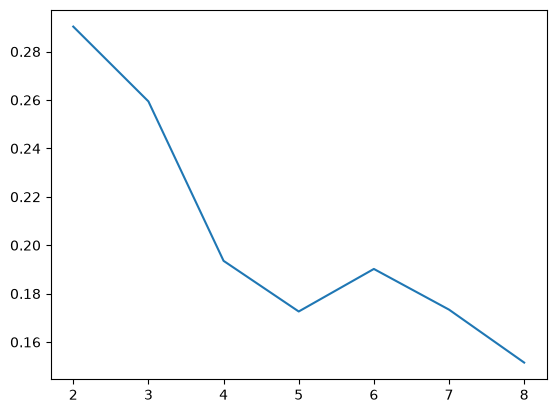

In [30]:
silhouettes = []
for k in range(2, 9):
    silhouettes.append(silhouette_score(X_log, KMeans(n_clusters=k).fit_predict(X_log)))
plt.plot(range(2, 9), silhouettes)

In [31]:
labels = KMeans(n_clusters=2).fit_predict(X_log)
pd.crosstab(labels, df["Channel"])

Channel,1,2
row_0,,
0,53,134
1,245,8


- Median yearly spend per segment: the description a business team reads

In [32]:
spend.groupby(labels).median()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,5396.0,7677.0,11522.0,1057.0,4508.0,1386.0
1,10405.0,1882.0,2406.0,2234.0,325.0,750.0


## Hierarchy, Density and Mixtures on Customers

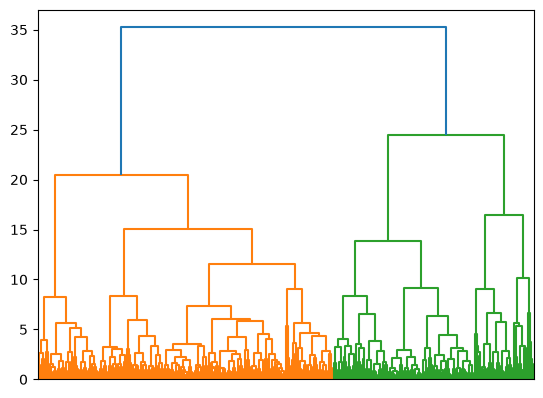

In [33]:
dendrogram(linkage(X_log, method="ward"), no_labels=True)
plt.show()

In [34]:
adjusted_rand_score(df["Channel"],
                    AgglomerativeClustering(n_clusters=2).fit_predict(X_log))

0.5392362707837141

In [35]:
hdb = HDBSCAN(copy=True).fit_predict(X_log)
(hdb == -1).mean(), hdb.max() + 1

(np.float64(0.45), np.int64(2))

In [36]:
gmm = GaussianMixture(n_components=2)
gmm.fit(X_log)
adjusted_rand_score(df["Channel"], gmm.predict(X_log))

0.6219667060605567

- Customers the mixture is unsure about

In [37]:
(gmm.predict_proba(X_log).max(axis=1) < 0.9).mean()

np.float64(0.11363636363636363)

## Lab: Four Segments

In [38]:
labels4 = KMeans(n_clusters=4).fit_predict(X_log)
spend.groupby(labels4).median()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,7861.0,1102.5,1788.0,1395.5,219.5,420.5
1,8190.0,9232.0,13462.0,1455.0,4973.0,1780.0
2,16764.0,3217.0,3444.5,3905.5,515.0,1362.5
3,1406.0,6264.0,9819.0,364.0,4095.0,314.0


In [39]:
pd.crosstab(labels4, df["Channel"])

Channel,1,2
row_0,,
0,123,1
1,19,92
2,127,9
3,29,40


- Give each segment a name a sales team would use
- Which segment mixes both channels, and what do its customers buy?

## Wrap-Up
- Slides 18-20